# Analyse des réservations d'hôtels

Les données utilisées sont le fichier nettoyé `data/processed/hotels_propre.csv` (voir `02_nettoyage.ipynb`). Chaque analyse répond à une des questions métier du notebook 01.

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)
sns.set_theme(style="whitegrid")

hotels = pd.read_csv(
    "../data/processed/hotels_propre.csv",
    parse_dates=["arrival_date", "reservation_status_date"],
)

hotels["hotel"] = hotels["hotel"].map({
    "City Hotel": "Hôtel de ville",
    "Resort Hotel": "Hôtel de villégiature",
})
hotels["deposit_type"] = hotels["deposit_type"].map({
    "No Deposit": "Sans dépôt",
    "Refundable": "Dépôt remboursable",
    "Non Refund": "Dépôt non remboursable",
})
hotels

,hotel,is_canceled,lead_time,arrival_date_week_number,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,arrival_date
0,Hôtel de villégiature,0,7,27,0,1,1,0,0,BB,...,0,Sans dépôt,0,0,Transient,75.00,0,0,2015-07-02,2015-07-01
1,Hôtel de villégiature,0,13,27,0,1,1,0,0,BB,...,0,Sans dépôt,304,0,Transient,75.00,0,0,2015-07-02,2015-07-01
2,Hôtel de villégiature,0,14,27,0,2,2,0,0,BB,...,0,Sans dépôt,240,0,Transient,98.00,0,1,2015-07-03,2015-07-01
3,Hôtel de villégiature,0,0,27,0,2,2,0,0,BB,...,0,Sans dépôt,0,0,Transient,107.00,0,0,2015-07-03,2015-07-01
4,Hôtel de villégiature,0,9,27,0,2,2,0,0,FB,...,0,Sans dépôt,303,0,Transient,103.00,0,1,2015-07-03,2015-07-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86623,Hôtel de ville,0,23,35,2,5,2,0,0,BB,...,0,Sans dépôt,394,0,Transient,96.14,0,0,2017-09-06,2017-08-30
86624,Hôtel de ville,0,102,35,2,5,3,0,0,BB,...,0,Sans dépôt,9,0,Transient,225.43,0,2,2017-09-07,2017-08-31
86625,Hôtel de ville,0,34,35,2,5,2,0,0,BB,...,0,Sans dépôt,9,0,Transient,157.71,0,4,2017-09-07,2017-08-31
86626,Hôtel de ville,0,109,35,2,5,2,0,0,BB,...,0,Sans dépôt,89,0,Transient,104.40,0,0,2017-09-07,2017-08-31


In [2]:
taux_annulation_global = hotels["is_canceled"].mean() * 100
print(f"Taux d'annulation global : {taux_annulation_global:.1f} %")

Taux d'annulation global : 27.7 %


In [3]:
taux_par_hotel = hotels.groupby("hotel").agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
taux_par_hotel["taux_annulation"] = (taux_par_hotel["taux_annulation"] * 100).round(1)
taux_par_hotel

,reservations,taux_annulation
hotel,,
Hôtel de ville,53038,30.2
Hôtel de villégiature,33590,23.7


In [4]:
taux_par_depot = hotels.groupby("deposit_type").agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
taux_par_depot["taux_annulation"] = (taux_par_depot["taux_annulation"] * 100).round(1)
taux_par_depot

,reservations,taux_annulation
deposit_type,,
Dépôt non remboursable,1037,94.7
Dépôt remboursable,107,24.3
Sans dépôt,85484,26.9


In [5]:
croisement_hotel_depot = (pd.pivot_table(
    hotels, values="is_canceled", index="hotel", columns="deposit_type", aggfunc="mean",
) * 100).round(1)
croisement_hotel_depot

deposit_type,Dépôt non remboursable,Dépôt remboursable,Sans dépôt
hotel,,,
Hôtel de ville,97.2,66.7,29.1
Hôtel de villégiature,83.9,17.4,23.4


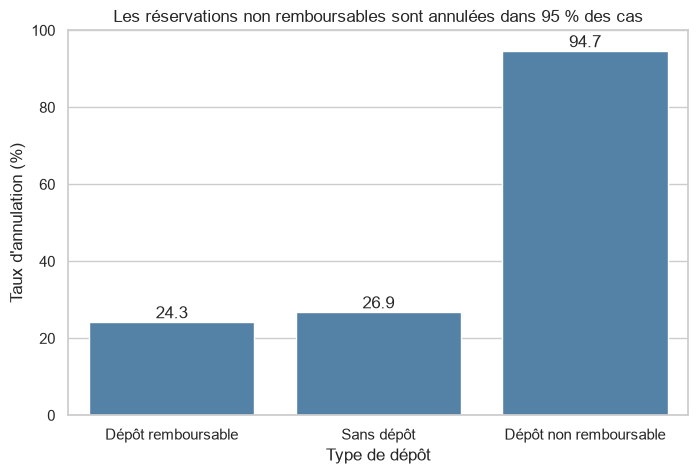

In [6]:
taux_depot_trie = (hotels.groupby("deposit_type")["is_canceled"].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=taux_depot_trie.index, y=taux_depot_trie.values, color="steelblue", ax=ax)
ax.set_title("Les réservations non remboursables sont annulées dans 95 % des cas")
ax.set_xlabel("Type de dépôt")
ax.set_ylabel("Taux d'annulation (%)")
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f")
fig.savefig("../figures/graphique_1_annulation_depot.png", dpi=150, bbox_inches="tight")
plt.show()

**Type de graphique : barres.** On compare un taux entre trois catégories de dépôt, triées de la plus basse à la plus haute.

**Réponse à la question 1 :** 27.7 % des réservations sont annulées. L'hôtel de ville annule davantage (30.2 %) que l'hôtel de villégiature (23.7 %). Le type de dépôt pèse encore plus : 94.7 % des réservations à dépôt non remboursable sont annulées, contre 26.9 % sans dépôt. Ce résultat est contre-intuitif et à interpréter avec prudence : ces réservations ne représentent que 1037 lignes (1,2 % du total) et le jeu de données ne dit pas pourquoi.

In [8]:
hotels["tranche_delai"] = pd.cut(
    hotels["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, 1000],
    labels=["0 à 7 jours", "8 à 30 jours", "31 à 90 jours",
            "91 à 180 jours", "181 à 365 jours", "plus de 365 jours"],
)

annulation_par_delai = hotels.groupby("tranche_delai", observed=True).agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
annulation_par_delai["taux_annulation"] = (annulation_par_delai["taux_annulation"] * 100).round(1)
annulation_par_delai

,reservations,taux_annulation
tranche_delai,,
0 à 7 jours,17851,8.5
8 à 30 jours,16231,25.5
31 à 90 jours,22633,32.1
91 à 180 jours,18188,35.1
181 à 365 jours,11164,39.8
plus de 365 jours,561,41.0


In [9]:
hotels.groupby("is_canceled")["lead_time"].median()

is_canceled
0    38.0
1    80.0
Name: lead_time, dtype: float64

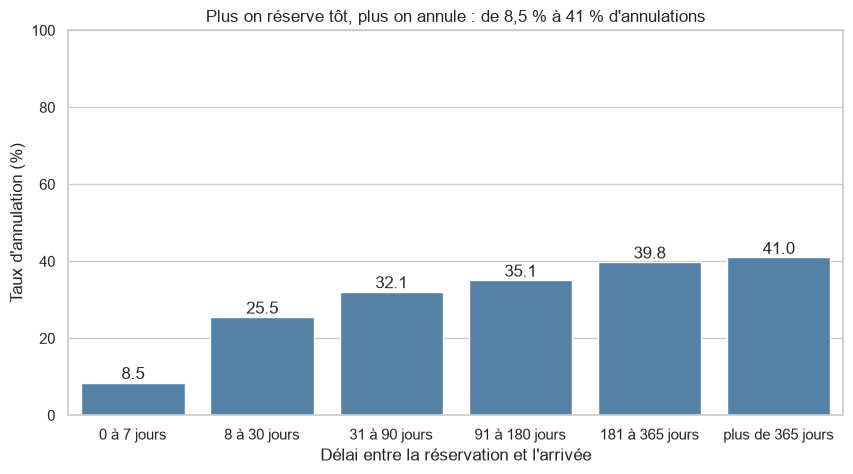

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=annulation_par_delai.index.astype(str),
    y=annulation_par_delai["taux_annulation"],
    color="steelblue", ax=ax,
)
ax.set_title("Plus on réserve tôt, plus on annule : de 8,5 % à 41 % d'annulations")
ax.set_xlabel("Délai entre la réservation et l'arrivée")
ax.set_ylabel("Taux d'annulation (%)")
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f")
fig.savefig("../figures/graphique_2_delai.png", dpi=150, bbox_inches="tight")
plt.show()

**Type de graphique : barres.** Les tranches de délai ont un ordre naturel (du plus court au plus long), qui est aussi l'ordre croissant des taux.

**Réponse à la question 2 :** Oui, le délai influence les annulations. Seulement 8.5 % des réservations faites moins d'une semaine avant l'arrivée sont annulées, contre 39.8 % à 41 % pour celles faites plus de six mois à l'avance. Le délai médian est de 38 jours pour les réservations maintenues et de 80 jours pour les annulées. Cette analyse montre un lien, pas une cause.